In [ ]:
'''Compare hyperparameter tuning strategies (Grid Search, Random Search, Bayesian Optimization, Optuna), 
analyzing their impact on model accuracy, convergence time, and computational efficiency.'''

In [1]:
# import libraries for data processing, optimization and evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from scipy.stats import randint

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_val_score

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from skopt import BayesSearchCV
from skopt.space import Integer, Categorical

import optuna


In [2]:
# load pharmacy sales dataset

df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)

display(df.head())

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [3]:
# clean data and separate input features and target variable

df = df.drop_duplicates()

df = df.drop(columns=["date"], errors="ignore")

df = df.dropna(subset=["units_sold"])

X = df.drop(columns=["units_sold"])
y = df["units_sold"]

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("numerical features:", numeric_features)
print("categorical features:", categorical_features)
print("target variable: units_sold")

numerical features: ['year', 'month', 'day', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
categorical features: ['region', 'country', 'category', 'medicine', 'age_group']
target variable: units_sold


In [4]:
# split data into training and testing datasets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# create a small tuning sample to reduce computational load

tuning_size = min(6000, len(X_train))
test_size = min(6000, len(X_test))

X_tuning = X_train.sample(
    n=tuning_size,
    random_state=42
)

y_tuning = y_train.loc[X_tuning.index]

X_evaluation = X_test.sample(
    n=test_size,
    random_state=42
)

y_evaluation = y_test.loc[X_evaluation.index]

print("tuning records:", len(X_tuning))
print("evaluation records:", len(X_evaluation))

tuning records: 6000
evaluation records: 6000


In [5]:
# prepare numerical and categorical data using a common preprocessing pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# use the same regression algorithm for a fair strategy comparison

base_model = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

def create_pipeline():
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ))
    ])

print("preprocessing and model pipeline created")

preprocessing and model pipeline created


In [6]:
# define the same search boundaries and validation strategy for all methods

cv = KFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

# grid search evaluates these eight combinations

grid_params = {
    "model__n_estimators": [30, 50],
    "model__max_depth": [8, 12],
    "model__min_samples_split": [2, 8]
}

# random and bayesian methods explore the broader search space

random_params = {
    "model__n_estimators": randint(30, 61),
    "model__max_depth": [8, 12, None],
    "model__min_samples_split": randint(2, 11)
}

bayesian_params = {
    "model__n_estimators": Integer(30, 60),
    "model__max_depth": Categorical([8, 12, None]),
    "model__min_samples_split": Integer(2, 10)
}

print("cross-validation folds:", cv.n_splits)
print("grid combinations:", 8)
print("random search iterations:", 8)
print("bayesian search iterations:", 8)
print("optuna trials:", 8)

cross-validation folds: 2
grid combinations: 8
random search iterations: 8
bayesian search iterations: 8
optuna trials: 8


In [7]:
# optimize model using exhaustive grid search

grid_start = time.time()

grid_search = GridSearchCV(
    estimator=create_pipeline(),
    param_grid=grid_params,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=2,
    refit=False,
    verbose=0
)

grid_search.fit(X_tuning, y_tuning)

grid_time = time.time() - grid_start

grid_best_params = grid_search.best_params_

grid_best_rmse = -grid_search.best_score_

grid_history = -grid_search.cv_results_["mean_test_score"]

print("grid search completed")
print("best parameters:", grid_best_params)
print("best cv rmse:", grid_best_rmse)
print("execution time:", round(grid_time, 2), "seconds")

grid search completed
best parameters: {'model__max_depth': 8, 'model__min_samples_split': 8, 'model__n_estimators': 50}
best cv rmse: 89.08640466938476
execution time: 14.39 seconds


In [8]:
# optimize model using random probabilistic parameter sampling

random_start = time.time()

random_search = RandomizedSearchCV(
    estimator=create_pipeline(),
    param_distributions=random_params,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=2,
    random_state=42,
    refit=False,
    verbose=0
)

random_search.fit(X_tuning, y_tuning)

random_time = time.time() - random_start

random_best_params = random_search.best_params_

random_best_rmse = -random_search.best_score_

random_history = -random_search.cv_results_["mean_test_score"]

print("random search completed")
print("best parameters:", random_best_params)
print("best cv rmse:", random_best_rmse)
print("execution time:", round(random_time, 2), "seconds")

random search completed
best parameters: {'model__max_depth': 8, 'model__min_samples_split': 8, 'model__n_estimators': 55}
best cv rmse: 89.12809924501335
execution time: 19.64 seconds


In [9]:
# optimize model using bayesian search guided by previous evaluations

bayes_start = time.time()

bayes_search = BayesSearchCV(
    estimator=create_pipeline(),
    search_spaces=bayesian_params,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=2,
    random_state=42,
    refit=False,
    verbose=0
)

bayes_search.fit(X_tuning, y_tuning)

bayes_time = time.time() - bayes_start

bayes_best_params = bayes_search.best_params_

bayes_best_rmse = -bayes_search.best_score_

bayes_history = -bayes_search.cv_results_["mean_test_score"]

print("bayesian optimization completed")
print("best parameters:", bayes_best_params)
print("best cv rmse:", bayes_best_rmse)
print("execution time:", round(bayes_time, 2), "seconds")

bayesian optimization completed
best parameters: OrderedDict({'model__max_depth': 12, 'model__min_samples_split': 8, 'model__n_estimators': 58})
best cv rmse: 89.92810316299656
execution time: 18.06 seconds


In [10]:
# optimize model using optuna tpe probabilistic sampling

optuna_history = []

def objective(trial):

    # select parameter values for the current trial

    params = {
        "model__n_estimators": trial.suggest_int(
            "n_estimators", 30, 60, step=10
        ),
        "model__max_depth": trial.suggest_categorical(
            "max_depth", [8, 12, None]
        ),
        "model__min_samples_split": trial.suggest_int(
            "min_samples_split", 2, 10
        )
    }

    # evaluate current configuration using cross-validation

    pipeline = create_pipeline()
    pipeline.set_params(**params)

    scores = cross_val_score(
        pipeline,
        X_tuning,
        y_tuning,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    current_rmse = -scores.mean()

    optuna_history.append(current_rmse)

    return current_rmse


# create and execute optuna study

optuna_start = time.time()

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=8,
    n_jobs=1,
    show_progress_bar=False
)

optuna_time = time.time() - optuna_start

optuna_best_params = {
    "model__" + key: value
    for key, value in study.best_params.items()
}

optuna_best_rmse = study.best_value

print("optuna optimization completed")
print("best parameters:", optuna_best_params)
print("best cv rmse:", optuna_best_rmse)
print("execution time:", round(optuna_time, 2), "seconds")

[I 2026-11-01 18:20:30,978] A new study created in memory with name: no-name-7155bfd6-baed-44c5-ba98-0d41d9599289
[I 2026-11-01 18:20:32,582] Trial 0 finished with value: 90.61094775100862 and parameters: {'n_estimators': 40, 'max_depth': 8, 'min_samples_split': 3}. Best is trial 0 with value: 90.61094775100862.
[I 2026-11-01 18:20:34,929] Trial 1 finished with value: 91.03774890835058 and parameters: {'n_estimators': 30, 'max_depth': 12, 'min_samples_split': 8}. Best is trial 0 with value: 90.61094775100862.
[I 2026-11-01 18:20:36,186] Trial 2 finished with value: 90.96079951279528 and parameters: {'n_estimators': 30, 'max_depth': 8, 'min_samples_split': 3}. Best is trial 0 with value: 90.61094775100862.
[I 2026-11-01 18:20:38,689] Trial 3 finished with value: 91.40753085785062 and parameters: {'n_estimators': 30, 'max_depth': 12, 'min_samples_split': 4}. Best is trial 0 with value: 90.61094775100862.
[I 2026-11-01 18:20:44,076] Trial 4 finished with value: 90.53777916308638 and param

optuna optimization completed
best parameters: {'model__n_estimators': 50, 'model__max_depth': None, 'model__min_samples_split': 6}
best cv rmse: 90.53777916308638
execution time: 33.96 seconds


In [11]:
# fit each optimized configuration and measure independent test performance

strategies = {
    "Grid Search": (grid_best_params, grid_time, grid_best_rmse),
    "Random Search": (random_best_params, random_time, random_best_rmse),
    "Bayesian Optimization": (bayes_best_params, bayes_time, bayes_best_rmse),
    "Optuna": (optuna_best_params, optuna_time, optuna_best_rmse)
}

comparison_results = []
trained_models = {}

for name, (params, search_time, cv_rmse) in strategies.items():

    # train the optimized model

    model = create_pipeline()
    model.set_params(**params)

    fit_start = time.time()
    model.fit(X_tuning, y_tuning)
    fit_time = time.time() - fit_start

    # predict on the same independent evaluation dataset

    predictions = model.predict(X_evaluation)

    # calculate performance metrics

    mae = mean_absolute_error(y_evaluation, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_evaluation, predictions)
    )

    r2 = r2_score(y_evaluation, predictions)

    total_time = search_time + fit_time

    trained_models[name] = model

    comparison_results.append({
        "Strategy": name,
        "CV RMSE": cv_rmse,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R2": r2,
        "Search Time (sec)": search_time,
        "Final Fit Time (sec)": fit_time,
        "Total Time (sec)": total_time,
        "Trials": 8,
        "Trials per Second": 8 / search_time if search_time > 0 else 0
    })

print("all optimized models evaluated")

all optimized models evaluated


In [12]:
# compare accuracy, convergence time and computational efficiency

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

display(comparison_df.round(4))

,Strategy,CV RMSE,Test MAE,Test RMSE,Test R2,Search Time (sec),Final Fit Time (sec),Total Time (sec),Trials,Trials per Second
0,Optuna,90.5378,67.2357,94.5327,0.9281,33.9589,7.8506,41.8096,8,0.2356
1,Random Search,89.1281,66.1692,94.9623,0.9274,19.6412,2.2553,21.8966,8,0.4073
2,Grid Search,89.0864,66.1869,95.2303,0.9270,14.3927,2.0699,16.4625,8,0.5558
3,Bayesian Optimization,89.9281,66.6353,95.8980,0.9260,18.0604,5.4953,23.5557,8,0.4430


In [13]:
# identify the strategy with the lowest independent test rmse

best_strategy = comparison_df.loc[0, "Strategy"]



print("best strategy:", best_strategy)

print("test rmse:",
      round(comparison_df.loc[0, "Test RMSE"], 4))

print("test mae:",
      round(comparison_df.loc[0, "Test MAE"], 4))

print("test r2:",
      round(comparison_df.loc[0, "Test R2"], 4))

print("total time:",
      round(comparison_df.loc[0, "Total Time (sec)"], 2),
      "seconds")

best strategy: Optuna
test rmse: 94.5327
test mae: 67.2357
test r2: 0.9281
total time: 41.81 seconds


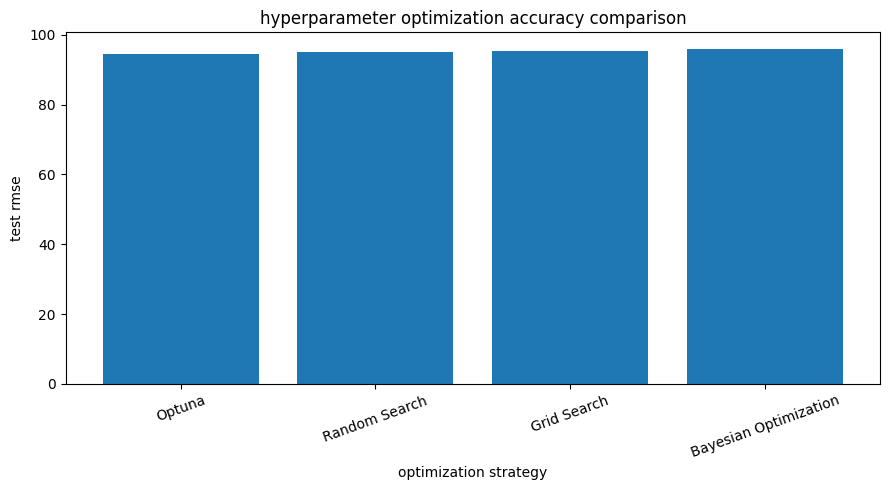

In [14]:
# visualize test rmse across all optimization strategies

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Strategy"],
    comparison_df["Test RMSE"]
)

plt.title("hyperparameter optimization accuracy comparison")
plt.xlabel("optimization strategy")
plt.ylabel("test rmse")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

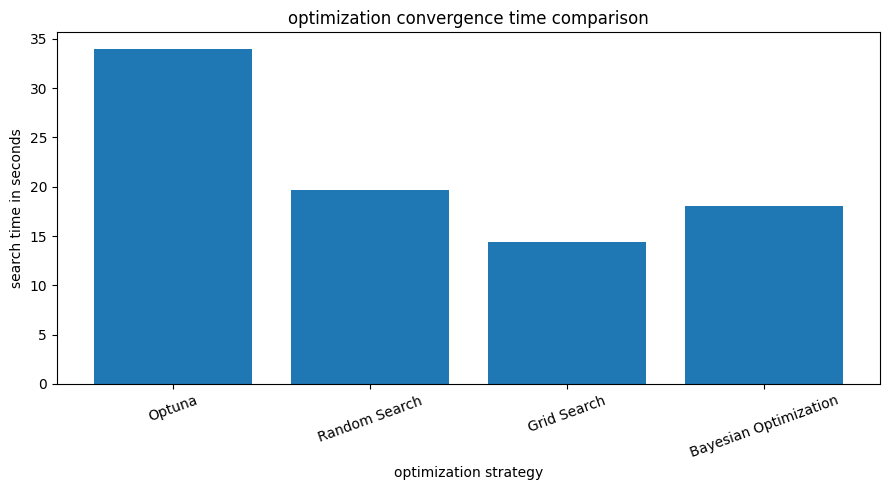

In [15]:
# compare search execution time for each optimization strategy

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Strategy"],
    comparison_df["Search Time (sec)"]
)

plt.title("optimization convergence time comparison")
plt.xlabel("optimization strategy")
plt.ylabel("search time in seconds")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

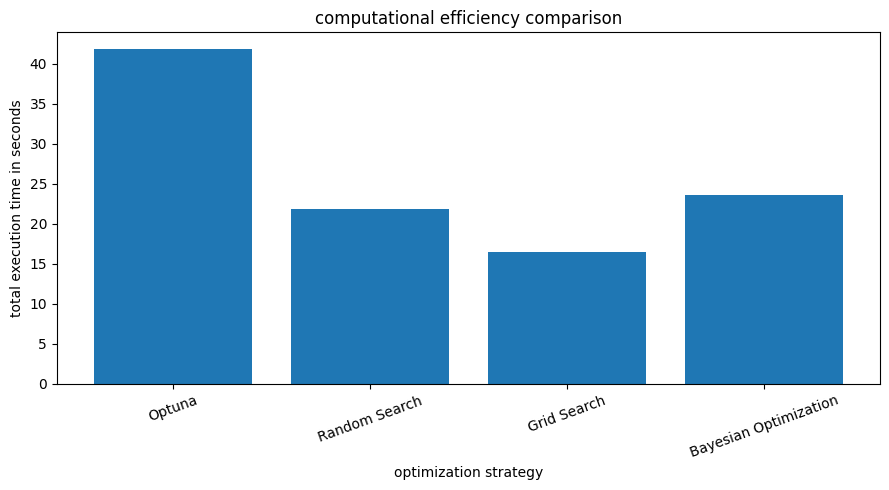

In [16]:
# compare total execution time including final model fitting

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Strategy"],
    comparison_df["Total Time (sec)"]
)

plt.title("computational efficiency comparison")
plt.xlabel("optimization strategy")
plt.ylabel("total execution time in seconds")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

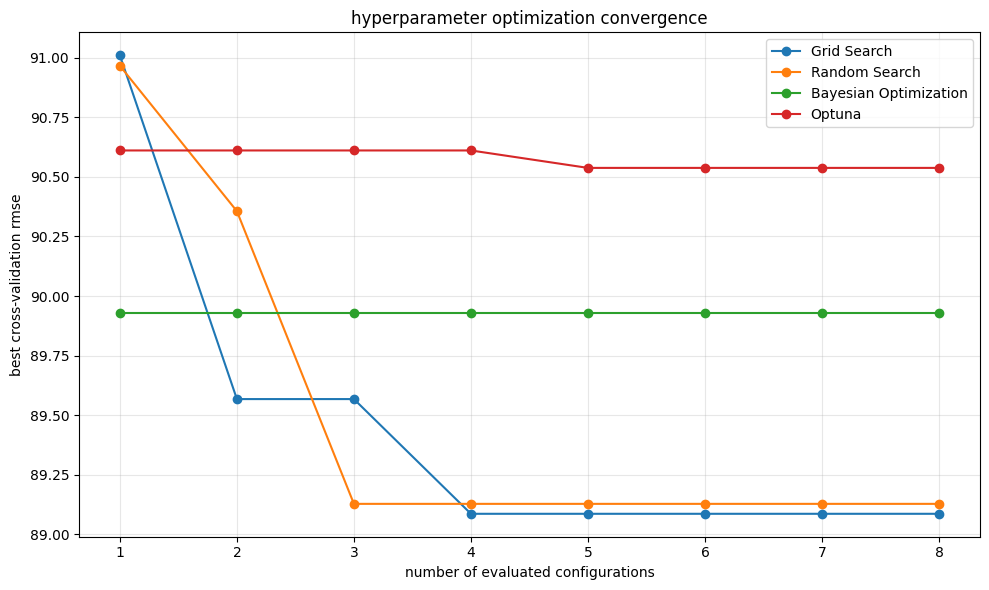

In [17]:
# compare how quickly each strategy finds better validation scores

convergence = {
    "Grid Search": grid_history,
    "Random Search": random_history,
    "Bayesian Optimization": bayes_history,
    "Optuna": optuna_history
}

plt.figure(figsize=(10, 6))

for name, history in convergence.items():

    # calculate best rmse found up to each trial

    best_so_far = np.minimum.accumulate(history)

    plt.plot(
        range(1, len(best_so_far) + 1),
        best_so_far,
        marker="o",
        label=name
    )

plt.title("hyperparameter optimization convergence")
plt.xlabel("number of evaluated configurations")
plt.ylabel("best cross-validation rmse")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# display the complete comparison and identify the most efficient method

fastest_strategy = comparison_df.loc[
    comparison_df["Total Time (sec)"].idxmin(), "Strategy"
]

best_accuracy = comparison_df.loc[
    comparison_df["Test RMSE"].idxmin(), "Strategy"
]

best_r2_strategy = comparison_df.loc[
    comparison_df["Test R2"].idxmax(), "Strategy"
]



print("\nstrategies evaluated: 4")

print("total trials per strategy: 8")

print("cross-validation folds: 2")

print("parallel processing: enabled for grid, random and bayesian search")

print("\nbest accuracy strategy:", best_accuracy)

print("best r2 strategy:", best_r2_strategy)

print("fastest strategy:", fastest_strategy)



display(comparison_df.round(4))

print("\nall hyperparameter optimization comparisons completed")


strategies evaluated: 4
total trials per strategy: 8
cross-validation folds: 2
parallel processing: enabled for grid, random and bayesian search

best accuracy strategy: Optuna
best r2 strategy: Optuna
fastest strategy: Grid Search

========== FINAL PERFORMANCE ==========


,Strategy,CV RMSE,Test MAE,Test RMSE,Test R2,Search Time (sec),Final Fit Time (sec),Total Time (sec),Trials,Trials per Second
0,Optuna,90.5378,67.2357,94.5327,0.9281,33.9589,7.8506,41.8096,8,0.2356
1,Random Search,89.1281,66.1692,94.9623,0.9274,19.6412,2.2553,21.8966,8,0.4073
2,Grid Search,89.0864,66.1869,95.2303,0.9270,14.3927,2.0699,16.4625,8,0.5558
3,Bayesian Optimization,89.9281,66.6353,95.8980,0.9260,18.0604,5.4953,23.5557,8,0.4430



all hyperparameter optimization comparisons completed
